# Olist 주문 데이터 시각화 및 추가 분석

목적: 주문 추이, 배송 지연과 저평점의 관계, 주문 금액 분포를 분석한다.

데이터 출처:
https://github.com/journal-izm/Olist-Data-Analysis

분석 질문:
1. 주문 수는 월별로 어떻게 변했을까?
2. 배송이 늦은 주문에서 저평점 비율이 높을까?
3. 주문 금액은 어느 구간에 몰려 있을까?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 차트 저장 폴더
Path("images").mkdir(exist_ok=True)

# GitHub 원본 데이터 주소
base_url = (
    "https://raw.githubusercontent.com/"
    "journal-izm/Olist-Data-Analysis/main/data/"
)

orders = pd.read_csv(base_url + "olist_orders_dataset.csv")
reviews = pd.read_csv(base_url + "olist_order_reviews_dataset.csv")
items = pd.read_csv(base_url + "olist_order_items_dataset.csv")

print("주문 데이터:", orders.shape)
print("리뷰 데이터:", reviews.shape)
print("주문 상품 데이터:", items.shape)

display(orders.head())

주문 데이터: (99441, 8)
리뷰 데이터: (99224, 7)
주문 상품 데이터: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [2]:
# 데이터별 행 수와 중복 확인
print("주문 데이터 행 수:", len(orders))
print("고유 주문 수:", orders["order_id"].nunique())
print("중복 주문 ID:", orders["order_id"].duplicated().sum())

print("\n리뷰 ID 중복:", reviews["review_id"].duplicated().sum())
print("주문 상품 중복:",
      items.duplicated(["order_id", "order_item_id"]).sum())

# 분석에 사용할 열의 결측치 확인
print("\n주문 데이터 결측치")
display(
    orders[[
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]].isna().sum().to_frame("결측치 수")
)

print("\n리뷰 점수 결측치:", reviews["review_score"].isna().sum())
print("상품 가격 결측치:", items["price"].isna().sum())

# 날짜 형식으로 변환
date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(
        orders[column], errors="coerce"
    )

print("\n날짜 변환 완료")
display(orders[date_columns].head())

주문 데이터 행 수: 99441
고유 주문 수: 99441
중복 주문 ID: 0

리뷰 ID 중복: 814
주문 상품 중복: 0

주문 데이터 결측치


,결측치 수
order_purchase_timestamp,0
order_delivered_customer_date,2965
order_estimated_delivery_date,0



리뷰 점수 결측치: 0
상품 가격 결측치: 0

날짜 변환 완료


,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18
1,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13
2,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04
3,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26


## 데이터 확인 및 전처리

주문 ID와 주문 상품의 중복 여부, 주요 변수의 결측치를 확인했다.
날짜 열은 날짜 형식으로 변환했다.
배송 완료일이 없는 주문은 일괄 삭제하지 않고 분석 목적에 따라 처리한다.

## 차트 1. 월별 주문 수

질문: 주문 수는 월별로 어떻게 변했을까?

집계 기준: 모든 주문 상태를 포함하며, 구매 날짜 기준으로 고유 주문 ID를 센다.

In [3]:
!apt-get -qq install -y fonts-nanum

import matplotlib.font_manager as fm

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)

plt.rcParams["font.family"] = fm.FontProperties(
    fname=font_path
).get_name()
plt.rcParams["axes.unicode_minus"] = False

print("한글 글꼴 설정 완료")

Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...
한글 글꼴 설정 완료


분석 기간: 2016-09-04 21:15:19 ~ 2018-10-17 17:30:18
최다 주문 월: 2017년 11월
해당 월 주문 수: 7,544건


,주문 수
order_purchase_timestamp,
2016-09-01,4
2016-10-01,324
2016-11-01,0
2016-12-01,1
2017-01-01,800
2017-02-01,1780
2017-03-01,2682
2017-04-01,2404
2017-05-01,3700


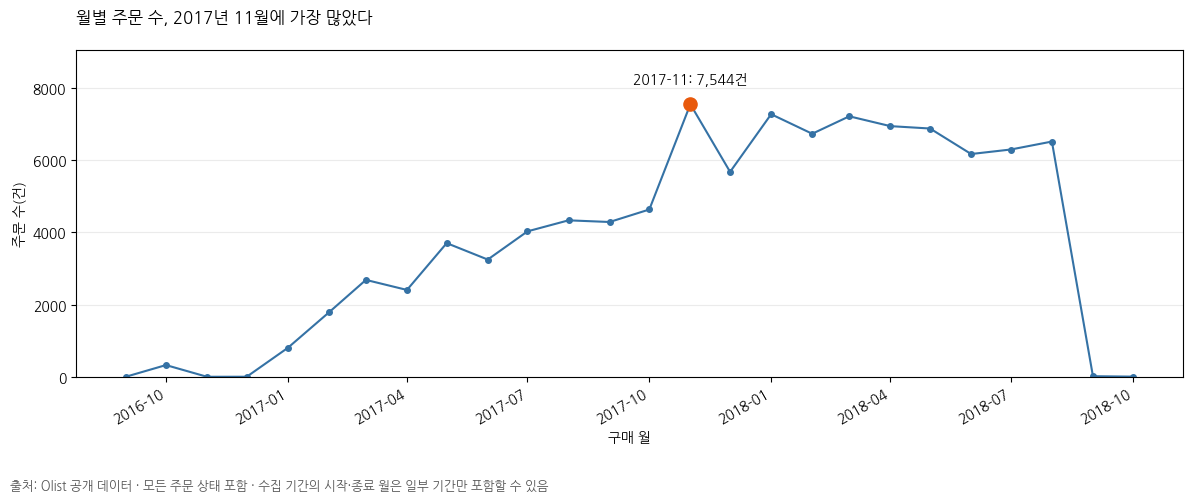

읽은 결과: 전체 주문 상태를 포함한 월별 집계에서 2017년 11월의 주문 수가 7,544건으로 가장 많았다.


In [4]:
# 구매 월별 고유 주문 수
monthly_orders = (
    orders.set_index("order_purchase_timestamp")["order_id"]
    .resample("MS")
    .nunique()
)

# 원본 주문 수와 집계 결과 비교
assert monthly_orders.sum() == orders["order_id"].nunique()

peak_month = monthly_orders.idxmax()
peak_count = int(monthly_orders.max())

print("분석 기간:",
      orders["order_purchase_timestamp"].min(),
      "~",
      orders["order_purchase_timestamp"].max())

print(f"최다 주문 월: {peak_month:%Y년 %m월}")
print(f"해당 월 주문 수: {peak_count:,}건")

display(monthly_orders.rename("주문 수").to_frame())

# 차트 그리기
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly_orders.index,
    monthly_orders.values,
    color="#3572A5",
    marker="o",
    markersize=4
)

# 주문이 가장 많은 달 강조
ax.scatter(
    peak_month,
    peak_count,
    color="#E8590C",
    s=90,
    zorder=3
)

ax.annotate(
    f"{peak_month:%Y-%m}: {peak_count:,}건",
    xy=(peak_month, peak_count),
    xytext=(0, 15),
    textcoords="offset points",
    ha="center"
)

ax.set_title(
    f"월별 주문 수, {peak_month:%Y년 %m월}에 가장 많았다",
    loc="left",
    pad=20
)
ax.set_xlabel("구매 월")
ax.set_ylabel("주문 수(건)")
ax.set_ylim(0, peak_count * 1.2)
ax.grid(axis="y", alpha=0.25)

fig.autofmt_xdate()
fig.text(
    0.01, 0.01,
    "출처: Olist 공개 데이터 · 모든 주문 상태 포함 · "
    "수집 기간의 시작·종료 월은 일부 기간만 포함할 수 있음",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.07, 1, 1])

# 화면 표시 전에 저장
fig.savefig(
    "images/01_monthly_orders.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"읽은 결과: 전체 주문 상태를 포함한 월별 집계에서 "
    f"{peak_month:%Y년 %m월}의 주문 수가 "
    f"{peak_count:,}건으로 가장 많았다."
)

읽은 결과: 모든 주문 상태를 포함해 구매 월별로 집계한 결과,
2017년 11월의 주문 수가 7,544건으로 가장 많았다.

주의: 수집 기간의 시작·종료 월은 일부 날짜만 포함할 수 있어,
해당 월의 낮은 주문 수를 실제 수요 감소로 단정하지 않는다.

## 차트 2. 배송 지연별 저평점 비율

질문: 배송이 늦은 주문에서 저평점 비율이 높을까?

집계 기준:
- 배송완료 주문 중 실제·예정 배송일이 있고 리뷰가 있는 주문만 분석한다.
- 한 주문에 리뷰가 여러 개면 마지막 응답 리뷰 한 건을 선택한다.
- 실제 배송 날짜가 예정 날짜보다 늦으면 지연 배송으로 분류한다.
- 리뷰 점수 1~2점을 저평점으로 정의한다.

,주문수,저평점수,저평점 비율(%)
정시·조기 배송,89443,8289,9.27
지연 배송,6381,3983,62.42


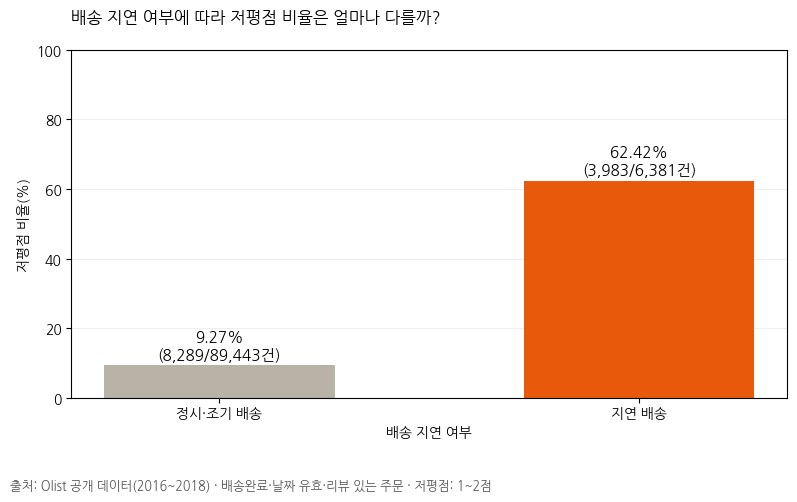

읽은 결과: 분석 대상에서 지연 배송의 저평점 비율은 62.42%로, 정시·조기 배송의 9.27%보다 높았다.
주의: 두 변수의 관계를 보여 주며 인과관계를 증명하지 않는다.


In [5]:
# 주문별 마지막 응답 리뷰 한 건 선택
review_one = reviews.copy()

review_one["review_answer_timestamp"] = pd.to_datetime(
    review_one["review_answer_timestamp"],
    errors="coerce"
)

review_one = (
    review_one
    .sort_values(
        ["review_answer_timestamp", "review_id"],
        na_position="first"
    )
    .drop_duplicates("order_id", keep="last")
)

# 배송완료 주문 중 날짜가 있는 주문 선택
delivery = orders.loc[
    orders["order_status"].eq("delivered")
].dropna(subset=[
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]).copy()

# 주문과 리뷰를 1:1로 연결
delivery = delivery.merge(
    review_one[["order_id", "review_score"]],
    on="order_id",
    how="inner",
    validate="one_to_one"
)

delivery = delivery.dropna(subset=["review_score"])

# 시간은 제외하고 날짜 단위로 비교
delivery["지연 여부"] = (
    delivery["order_delivered_customer_date"].dt.normalize()
    > delivery["order_estimated_delivery_date"].dt.normalize()
)

delivery["저평점"] = delivery["review_score"].le(2)

# 지연 여부별 주문 수와 저평점 비율
summary = (
    delivery.groupby("지연 여부")
    .agg(
        주문수=("order_id", "nunique"),
        저평점수=("저평점", "sum")
    )
    .reindex([False, True])
)

summary.index = ["정시·조기 배송", "지연 배송"]
summary["저평점 비율(%)"] = (
    summary["저평점수"] / summary["주문수"] * 100
)

display(summary.round(2))

# 차트
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    summary.index,
    summary["저평점 비율(%)"],
    color=["#B8B2A7", "#E8590C"],
    width=0.55
)

for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{row['저평점 비율(%)']:.2f}%\n"
        f"({int(row['저평점수']):,}/{int(row['주문수']):,}건)",
        ha="center",
        fontsize=11
    )

ax.set_title(
    "배송 지연 여부에 따라 저평점 비율은 얼마나 다를까?",
    loc="left",
    pad=20
)
ax.set_ylabel("저평점 비율(%)")
ax.set_xlabel("배송 지연 여부")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.01, 0.01,
    "출처: Olist 공개 데이터(2016~2018) · "
    "배송완료·날짜 유효·리뷰 있는 주문 · 저평점: 1~2점",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.08, 1, 1])

fig.savefig(
    "images/02_delivery_reviews.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

on_time_rate = summary.loc["정시·조기 배송", "저평점 비율(%)"]
late_rate = summary.loc["지연 배송", "저평점 비율(%)"]

print(
    f"읽은 결과: 분석 대상에서 지연 배송의 저평점 비율은 "
    f"{late_rate:.2f}%로, 정시·조기 배송의 "
    f"{on_time_rate:.2f}%보다 높았다."
)
print("주의: 두 변수의 관계를 보여 주며 인과관계를 증명하지 않는다.")

읽은 결과: 분석 대상에서 지연 배송의 저평점 비율은 62.42%로, 정시·조기 배송의 9.27%보다 높았다.
주의: 두 변수의 관계를 보여 주며 인과관계를 증명하지 않는다.

## 차트 3. 주문 금액 분포

질문: 주문 상품 금액은 어느 구간에 몰려 있을까?

집계 기준:
- 상품 데이터에 있는 주문을 대상으로 한다.
- 주문별 상품 가격(price)을 합산한다.
- 배송비는 제외하며, 단위는 브라질 헤알(BRL)이다.
- 분포를 자세히 보기 위해 하위 99% 구간을 표시하고,
  상위 1%에 해당하는 주문 수도 따로 밝힌다.

전체 분석 주문 수: 98,666건
주문 상품 금액 중앙값: 86.90 BRL
99백분위 금액: 998.90 BRL
차트 범위 밖 주문 수: 986건


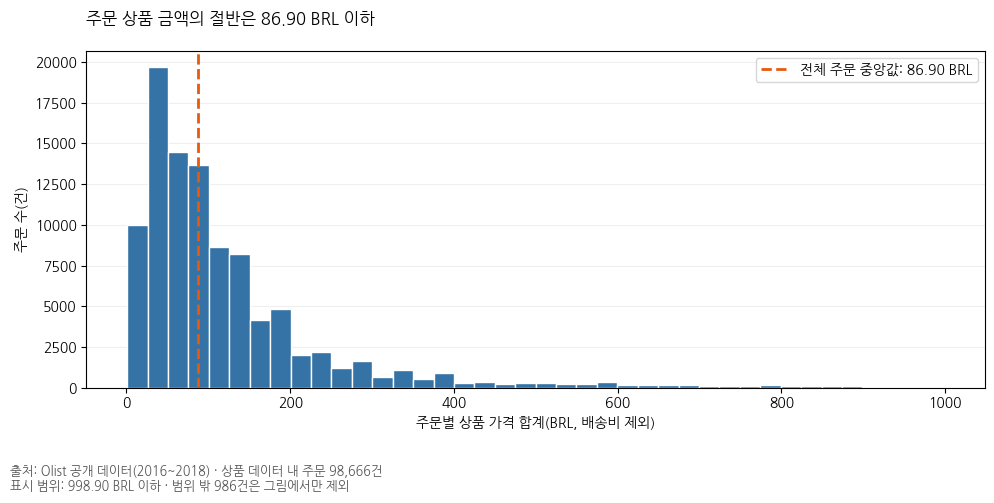

읽은 결과: 상품 데이터에 있는 주문의 상품 가격 합계 중앙값은 86.90 BRL로, 주문의 절반은 이 금액 이하였다.


In [6]:
# 주문별 상품 가격 합계: 배송비 제외
order_amount = items.groupby("order_id")["price"].sum()

assert items["price"].notna().all()
assert (order_amount >= 0).all()

median_amount = order_amount.median()
cutoff = order_amount.quantile(0.99)

# 차트 표시 범위만 제한하며 원본 데이터는 유지
shown = order_amount[order_amount <= cutoff]
excluded_count = int((order_amount > cutoff).sum())

print(f"전체 분석 주문 수: {len(order_amount):,}건")
print(f"주문 상품 금액 중앙값: {median_amount:,.2f} BRL")
print(f"99백분위 금액: {cutoff:,.2f} BRL")
print(f"차트 범위 밖 주문 수: {excluded_count:,}건")

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    shown,
    bins=40,
    color="#3572A5",
    edgecolor="white"
)

ax.axvline(
    median_amount,
    color="#E8590C",
    linestyle="--",
    linewidth=2,
    label=f"전체 주문 중앙값: {median_amount:,.2f} BRL"
)

ax.set_title(
    f"주문 상품 금액의 절반은 {median_amount:,.2f} BRL 이하",
    loc="left",
    pad=20
)
ax.set_xlabel("주문별 상품 가격 합계(BRL, 배송비 제외)")
ax.set_ylabel("주문 수(건)")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.01, 0.01,
    f"출처: Olist 공개 데이터(2016~2018) · "
    f"상품 데이터 내 주문 {len(order_amount):,}건\n"
    f"표시 범위: {cutoff:,.2f} BRL 이하 · "
    f"범위 밖 {excluded_count:,}건은 그림에서만 제외",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    "images/03_order_amount.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(
    f"읽은 결과: 상품 데이터에 있는 주문의 "
    f"상품 가격 합계 중앙값은 {median_amount:,.2f} BRL로, "
    f"주문의 절반은 이 금액 이하였다."
)

읽은 결과: 상품 데이터에 있는 주문의 상품 가격 합계 중앙값은 86.90 BRL로, 주문의 절반은 이 금액 이하였다.

읽은 결과: 상품 데이터에 있는 주문 98,666건의 상품 가격 합계
중앙값은 86.90 BRL로, 주문의 절반은 이 금액 이하였다.

주의: 배송비를 제외한 금액이며, 998.90 BRL를 초과하는
986건은 차트 표시에서만 제외했다.

In [7]:
from pathlib import Path

png_files = [
    Path("images/01_monthly_orders.png"),
    Path("images/02_delivery_reviews.png"),
    Path("images/03_order_amount.png")
]

for file in png_files:
    assert file.exists(), f"파일이 없습니다: {file}"
    print(f"확인: {file.name} ({file.stat().st_size:,} bytes)")

확인: 01_monthly_orders.png (117,359 bytes)
확인: 02_delivery_reviews.png (86,254 bytes)
확인: 03_order_amount.png (99,971 bytes)


In [8]:
import zipfile
from google.colab import files

with zipfile.ZipFile("Olist_차트3장.zip", "w") as zip_file:
    for file in png_files:
        zip_file.write(file, arcname=str(file))

files.download("Olist_차트3장.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>